# Startup Outcomes: Acquired or Closed?
## AI and Big Data Analytics — Weeks 4 to 8 assessment

**Student:**
**Student ID and group:**
**Dataset:** Startup Success Prediction (Crunchbase extract), Kaggle, `manishkc06/startup-success-prediction`
**Random seed:** 42

Run all cells from top to bottom. The notebook reads `data/startup_data_original.csv` and writes the analytical dataset to `data/startup_data_analytical.csv`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay,
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score
)
from sklearn.exceptions import ConvergenceWarning
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore', category=ConvergenceWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA_PATH = Path('data/startup_data_original.csv')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)
print('Random state:', RANDOM_STATE)

Random state: 42


## 1. Load the data and confirm its size

In [2]:
if not DATA_PATH.exists():
    # Colab fallback: upload the CSV manually
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH.parent.mkdir(exist_ok=True)
    Path(next(iter(uploaded))).rename(DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print('Rows, columns:', raw.shape)
assert raw.shape == (923, 49), 'Row or column count does not match the supplied file.'
display(raw.head(3).T)

Rows, columns: (923, 49)


,0,1,2
Unnamed: 0,1005,204,1001
state_code,CA,CA,CA
latitude,42.359,37.239,32.901
longitude,-71.057,-121.974,-117.193
zip_code,92101,95032,92121
id,c:6669,c:16283,c:65620
city,San Diego,Los Gatos,San Diego
Unnamed: 6,NaN,NaN,San Diego CA 92121
name,Bandsintown,TriCipher,Plixi
labels,1,1,1


**Interpretation.** The file loads with 923 rows and 49 columns. This matches the supplied CSV. One row is one US startup from a Crunchbase extract. The outcome is `status`: acquired or closed. No firm is still operating, so the data hold only resolved outcomes.

## 2. Data audit

In [3]:
audit = raw.copy()
for c in ['founded_at', 'closed_at', 'first_funding_at', 'last_funding_at']:
    audit[c] = pd.to_datetime(audit[c], format='%m/%d/%Y', errors='coerce')

missing = audit.isna().agg(['sum', 'mean']).T.rename(columns={'sum': 'missing_n', 'mean': 'missing_share'})
display(missing[missing['missing_n'] > 0].sort_values('missing_n', ascending=False))

state_dummies = ['is_CA', 'is_NY', 'is_MA', 'is_TX', 'is_otherstate']
checks = pd.Series({
    'Exact duplicate rows': audit.duplicated().sum(),
    'Duplicate company id': audit['id'].duplicated().sum(),
    'id equal to object_id (rows)': (audit['id'] == audit['object_id']).sum(),
    'labels disagree with status': ((audit['labels'] == 1) != (audit['status'] == 'acquired')).sum(),
    'state_code differs from state_code.1': (audit['state_code'] != audit['state_code.1']).sum(),
    'Rows with no state dummy set': (audit[state_dummies].sum(axis=1) == 0).sum(),
    'Negative age_first_funding_year': (audit['age_first_funding_year'] < 0).sum(),
    'Negative age_last_funding_year': (audit['age_last_funding_year'] < 0).sum(),
    'Negative age_first_milestone_year': (audit['age_first_milestone_year'] < 0).sum(),
    'Missing milestone age and milestones == 0': (audit['age_first_milestone_year'].isna() & (audit['milestones'] == 0)).sum(),
    'Acquired but closed_at filled': ((audit['status'] == 'acquired') & audit['closed_at'].notna()).sum(),
    'Closed with closed_at filled': ((audit['status'] == 'closed') & audit['closed_at'].notna()).sum(),
    'Founded before 2000': (audit['founded_at'].dt.year < 2000).sum(),
    'Closed rate if founded before 2000': (audit.loc[audit['founded_at'].dt.year < 2000, 'status'] == 'closed').mean(),
})
display(checks.to_frame('value'))
print('Founded range:', audit['founded_at'].min().date(), 'to', audit['founded_at'].max().date())
print('Last funding range:', audit['last_funding_at'].min().date(), 'to', audit['last_funding_at'].max().date())

,missing_n,missing_share
closed_at,588.000,0.637
Unnamed: 6,493.000,0.534
age_first_milestone_year,152.000,0.165
age_last_milestone_year,152.000,0.165
state_code.1,1.000,0.001


,value
Exact duplicate rows,0.000
Duplicate company id,1.000
id equal to object_id (rows),923.000
labels disagree with status,0.000
state_code differs from state_code.1,1.000
Rows with no state dummy set,1.000
Negative age_first_funding_year,46.000
Negative age_last_funding_year,13.000
Negative age_first_milestone_year,46.000
Missing milestone age and milestones == 0,152.000


Founded range: 1984-01-01 to 2013-04-16
Last funding range: 2001-01-01 to 2013-11-20


In [4]:
# Possible outliers: valid extremes or errors?
skewed = ['funding_total_usd', 'relationships', 'avg_participants', 'funding_rounds', 'milestones']
q = audit[skewed].quantile([0.5, 0.99]).T
q['max'] = audit[skewed].max()
q['n_above_3x_IQR'] = [
    int((audit[c] > audit[c].quantile(.75) + 3 * (audit[c].quantile(.75) - audit[c].quantile(.25))).sum())
    for c in skewed
]
display(q)
display(audit.nlargest(5, 'funding_total_usd')[['name', 'category_code', 'funding_total_usd', 'funding_rounds', 'status']])
display(audit.loc[audit['age_first_funding_year'] < 0, ['founded_at', 'first_funding_at', 'age_first_funding_year']]
        .describe().T)

,0.500,0.990,max,n_above_3x_IQR
funding_total_usd,"10,000,000.000","134,473,544.600","5,700,000,000.000",19
relationships,5.000,35.000,63.000,13
avg_participants,2.500,9.000,16.000,4
funding_rounds,2.000,7.000,10.000,1
milestones,2.000,5.000,8.000,0


,name,category_code,funding_total_usd,funding_rounds,status
364,Clearwire,mobile,5700000000,4,acquired
82,Abound Solar,cleantech,510000000,2,closed
28,"RetailMeNot, Inc.",web,299500000,5,acquired
497,ExactTarget,software,238209999,7,acquired
728,Pearl Therapeutics,biotech,232000100,6,acquired


,count,mean,min,25%,50%,75%,max,std
founded_at,46,2008-06-06 13:02:36.521739,2002-11-17 00:00:00,2007-01-08 18:00:00,2008-06-01 00:00:00,2010-01-01 00:00:00,2013-04-16 00:00:00,NaN
first_funding_at,46,2007-09-29 04:10:26.086956,2002-11-01 00:00:00,2006-07-08 18:00:00,2007-09-16 00:00:00,2009-05-16 18:00:00,2012-06-01 00:00:00,NaN
age_first_funding_year,46.000,-0.689,-9.047,-0.836,-0.251,-0.119,-0.003,1.410


**Interpretation.** The data are usable but not clean.

- `closed_at` is missing for 588 rows. That is not a defect. It is filled for all 326 closed firms and for 9 acquired ones. It encodes the answer.
- 152 firms lack a milestone age. All 152 have zero milestones. Missing here means "no milestone", not "lost value".
- 46 firms show first funding before founding. The median gap is three months. This looks like a founding date entered late, not a real event. I set these ages to missing.
- One company, Redwood Systems, appears twice with identical values except coordinates. I keep one row.
- `Unnamed: 0`, `Unnamed: 6` and `state_code.1` are export debris. `object_id` repeats `id`.
- Funding is extreme: median $10M, maximum $5.7B (Clearwire). These are real firms, not typos. I keep them and use a log scale.
- All 26 firms founded before 2000 closed. That is a sampling artefact, not a law.

### Cleaning and feature construction

Every rule below is row-wise. Nothing here learns from the data, so it can run before the split.
Imputation and scaling are fitted later, on training data only.

In [5]:
df = audit.copy()
df['closed'] = (df['status'] == 'closed').astype(int)          # positive class = closed

# Negative first-funding age: funding dated before the recorded founding date.
df['neg_first_funding'] = (df['age_first_funding_year'] < 0).astype(int)
df.loc[df['age_first_funding_year'] < 0, 'age_first_funding_year'] = np.nan
df.loc[df['age_first_milestone_year'] < 0, 'age_first_milestone_year'] = np.nan
# Missing milestone age = no milestone. Left as NaN, imputed with an indicator inside the pipeline.

df['log_funding_total'] = np.log1p(df['funding_total_usd'])
df['log_relationships'] = np.log1p(df['relationships'])

n_before = len(df)
df = df.drop_duplicates(subset='id', keep='first')   # Redwood Systems appears twice, identical except coordinates
print('Duplicate id rows removed:', n_before - len(df))

drop_cols = ['Unnamed: 0', 'Unnamed: 6', 'state_code.1', 'object_id', 'zip_code', 'latitude', 'longitude']
df = df.drop(columns=drop_cols)
print('Analytical rows, columns:', df.shape)

Duplicate id rows removed: 1
Analytical rows, columns: (922, 46)


### Feature availability and leakage check

In [6]:
NUM_FEATURES = ['age_first_funding_year', 'age_first_milestone_year', 'log_relationships',
                'funding_rounds', 'log_funding_total', 'milestones', 'avg_participants']
BIN_FEATURES = ['is_CA', 'is_NY', 'is_MA', 'is_TX',
                'is_software', 'is_web', 'is_mobile', 'is_enterprise', 'is_advertising',
                'is_gamesvideo', 'is_ecommerce', 'is_biotech',
                'has_VC', 'has_angel', 'has_roundA', 'has_roundB', 'has_roundC', 'has_roundD']
FEATURES = NUM_FEATURES + BIN_FEATURES

leakage = pd.DataFrame([
    ['status, labels', 'No', 'Exclude', 'Outcome itself; labels is a 0/1 copy of status.'],
    ['closed_at', 'No', 'Exclude', 'Filled for 326/326 closed firms. Reveals the outcome.'],
    ['age_last_funding_year, last_funding_at', 'No', 'Exclude', 'Timing of last activity is cut short by closure.'],
    ['age_last_milestone_year', 'No', 'Exclude', 'Same problem: last activity date depends on survival.'],
    ['is_top500', 'Unclear', 'Exclude', 'Not documented. Ranking date unknown, may follow the outcome.'],
    ['Funding counts, rounds, relationships, milestones', 'Yes, as history to date', 'Include with caution', 'Cumulative. Closed firms stop accumulating, so effects may be inflated.'],
    ['Age at first funding / first milestone', 'Yes', 'Include', 'Fixed once the first event happens.'],
    ['State and category dummies', 'Yes', 'Include', 'Known at founding. is_otherstate and is_othercategory are reference levels.'],
    ['is_consulting', 'Yes', 'Exclude', 'Only 3 firms. Too rare to estimate.'],
    ['id, name, city, zip, lat/long', 'Yes', 'Exclude', 'Identifiers or covered by state dummies.'],
    ['founded_at', 'Yes', 'Use for split only', 'Drives the temporal split. Not a feature, to avoid extrapolation.'],
], columns=['Variable or group', 'Available at decision time', 'Include or exclude', 'Justification'])
display(leakage)
print('Model features:', len(FEATURES))

,Variable or group,Available at decision time,Include or exclude,Justification
0,"status, labels",No,Exclude,Outcome itself; labels is a 0/1 copy of status.
1,closed_at,No,Exclude,Filled for 326/326 closed firms. Reveals the o...
2,"age_last_funding_year, last_funding_at",No,Exclude,Timing of last activity is cut short by closure.
3,age_last_milestone_year,No,Exclude,Same problem: last activity date depends on su...
4,is_top500,Unclear,Exclude,"Not documented. Ranking date unknown, may foll..."
5,"Funding counts, rounds, relationships, milestones","Yes, as history to date",Include with caution,"Cumulative. Closed firms stop accumulating, so..."
6,Age at first funding / first milestone,Yes,Include,Fixed once the first event happens.
7,State and category dummies,Yes,Include,Known at founding. is_otherstate and is_otherc...
8,is_consulting,Yes,Exclude,Only 3 firms. Too rare to estimate.
9,"id, name, city, zip, lat/long",Yes,Exclude,Identifiers or covered by state dummies.


Model features: 25


## 3. Evaluation design: temporal split

In [7]:
df = df.sort_values(['founded_at', 'id']).reset_index(drop=True)
n = len(df)
cut_dev, cut_train = int(n * 0.80), int(n * 0.80 * 0.80)
df['split'] = 'test'
df.loc[:cut_dev - 1, 'split'] = 'validation'
df.loc[:cut_train - 1, 'split'] = 'train'

train = df[df['split'] == 'train'].copy()
val = df[df['split'] == 'validation'].copy()
test = df[df['split'] == 'test'].copy()
dev = pd.concat([train, val])

split_table = df.groupby('split', sort=False).agg(
    n=('closed', 'size'), closed_rate=('closed', 'mean'),
    founded_from=('founded_at', 'min'), founded_to=('founded_at', 'max'))
split_table['share'] = split_table['n'] / n
display(split_table)

X_train, y_train = train[FEATURES], train['closed']
X_val, y_val = val[FEATURES], val['closed']
X_dev, y_dev = dev[FEATURES], dev['closed']
X_test, y_test = test[FEATURES], test['closed']

out = df.drop(columns=['status']).copy()
out.to_csv('data/startup_data_analytical.csv', index=False)
print('Saved data/startup_data_analytical.csv', out.shape)

,n,closed_rate,founded_from,founded_to,share
split,,,,,
train,590,0.327,1984-01-01,2007-04-01,0.640
validation,147,0.333,2007-04-01,2009-01-01,0.159
test,185,0.454,2009-01-01,2013-04-16,0.201


Saved data/startup_data_analytical.csv (922, 46)


**Interpretation.** I split by founding date, not at random. The intended user screens new startups. A model must work on firms younger than those it learned from. Train holds 590 firms founded 1984 to April 2007. Validation holds 147 firms, April 2007 to 2008. Test holds 185 firms, 2009 to 2013. The closed rate rises from 0.327 in train to 0.454 in test. Young firms in this extract fail more often, or are recorded only when they fail fast. Either way, the test is harder than the past. The seed is 42.

## 4. Exploratory analysis

In [8]:
desc_cols = ['funding_total_usd', 'funding_rounds', 'relationships', 'milestones',
             'avg_participants', 'age_first_funding_year', 'age_first_milestone_year']
desc = train[desc_cols].describe(percentiles=[.25, .5, .75]).T
desc['IQR'] = desc['75%'] - desc['25%']
desc['skewness'] = train[desc_cols].skew()
desc['missing'] = train[desc_cols].isna().sum()
print('Descriptive statistics, training partition (n = %d)' % len(train))
display(desc[['count', 'missing', 'mean', '50%', 'std', 'min', 'max', 'IQR', 'skewness']])

print('Target distribution by partition')
display(pd.crosstab(df['split'], df['status'], margins=True))

Descriptive statistics, training partition (n = 590)


,count,missing,mean,50%,std,min,max,IQR,skewness
funding_total_usd,590.000,0,"34,506,313.386","15,000,000.000","236,132,616.961","50,000.000","5,700,000,000.000","22,500,000.000",23.546
funding_rounds,590.000,0,2.498,2.000,1.502,1.000,10.000,2.000,1.238
relationships,590.000,0,8.012,6.000,7.795,0.000,63.000,7.000,2.342
milestones,590.000,0,1.741,1.000,1.436,0.000,8.000,2.000,0.772
avg_participants,590.000,0,2.837,2.500,1.593,1.000,10.000,2.250,1.243
age_first_funding_year,575.000,15,3.130,2.526,2.670,0.000,21.896,3.405,2.115
age_first_milestone_year,445.000,145,4.469,4.003,2.881,0.000,24.685,3.603,1.400


Target distribution by partition


status,acquired,closed,All
split,,,
test,101,84,185
train,397,193,590
validation,98,49,147
All,596,326,922


**Figure 1. Question: is total funding skewed enough to need a log scale, and does it differ by outcome?**

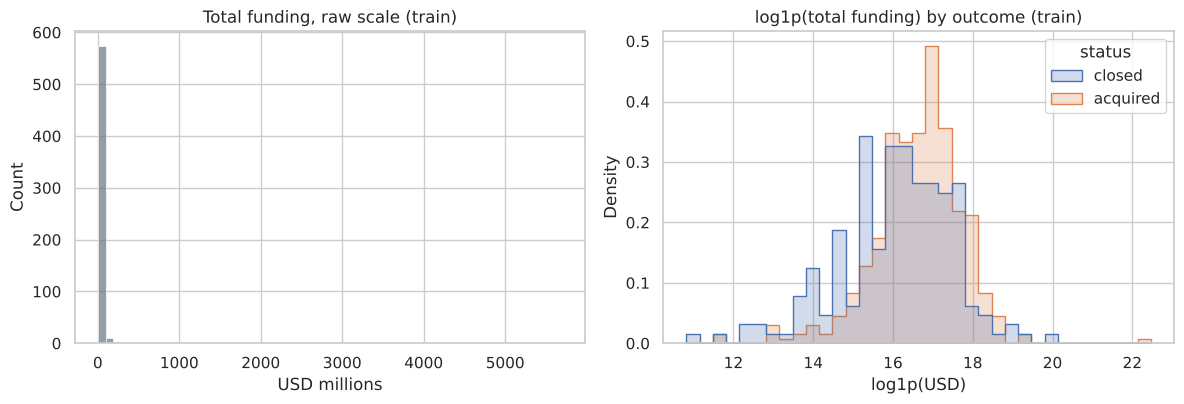

status
acquired   18.250
closed     10.600
Name: median, USD m, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(train['funding_total_usd'] / 1e6, bins=60, ax=axes[0], color='#6F7F89')
axes[0].set(title='Total funding, raw scale (train)', xlabel='USD millions')
sns.histplot(data=train, x='log_funding_total', hue='status', bins=35, stat='density',
             common_norm=False, element='step', ax=axes[1])
axes[1].set(title='log1p(total funding) by outcome (train)', xlabel='log1p(USD)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig1_funding.png', dpi=150); plt.show()
print(train.groupby('status')['funding_total_usd'].median().div(1e6).round(2).rename('median, USD m'))

**Interpretation.** Raw funding is useless on a linear axis. Skewness is 23.5 and a few firms dwarf the rest. On a log scale the shape is close to bell-like. Acquired firms sit to the right. Median funding is $18.3M for acquired and $10.6M for closed firms in train (n = 590). The two curves overlap heavily. Funding alone will not separate them.

*Limitation:* total funding is cumulative. A firm that closed early had less time to raise.

**Figure 2. Question: how does the closed rate change with network size and number of milestones?**

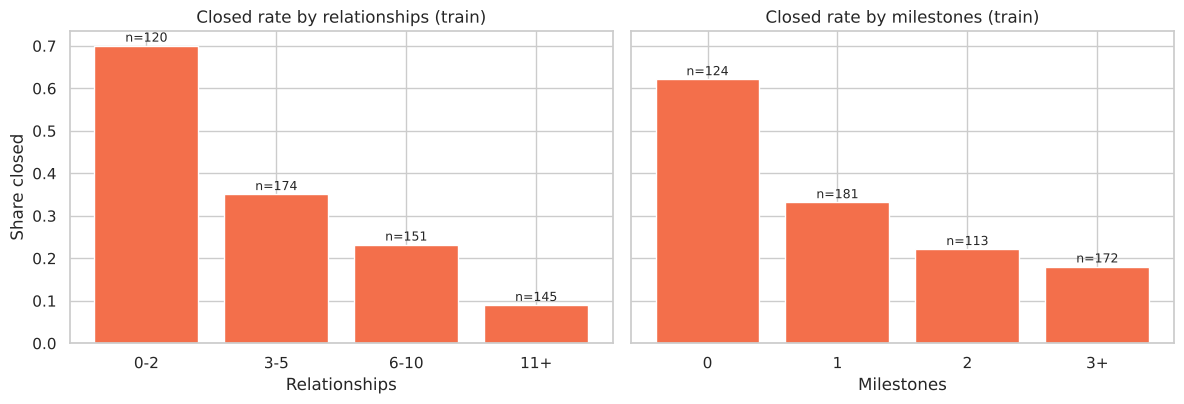

,size,mean
relationships_band,,
0-2,120,0.700
3-5,174,0.351
6-10,151,0.232
11+,145,0.090


,size,mean
milestones_band,,
0,124,0.621
1,181,0.331
2,113,0.221
3+,172,0.180


In [10]:
tmp = train.copy()
tmp['relationships_band'] = pd.cut(tmp['relationships'], [-1, 2, 5, 10, 100], labels=['0-2', '3-5', '6-10', '11+'])
tmp['milestones_band'] = pd.cut(tmp['milestones'], [-1, 0, 1, 2, 10], labels=['0', '1', '2', '3+'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, col, title in [(axes[0], 'relationships_band', 'Relationships'), (axes[1], 'milestones_band', 'Milestones')]:
    g = tmp.groupby(col, observed=True)['closed'].agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'], color='#F36F4B')
    for i, (m, s) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, m + .01, f'n={s}', ha='center', fontsize=9)
    ax.set(title=f'Closed rate by {title.lower()} (train)', xlabel=title)
axes[0].set_ylabel('Share closed')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig2_closed_rate.png', dpi=150); plt.show()
display(tmp.groupby('relationships_band', observed=True)['closed'].agg(['size', 'mean']))
display(tmp.groupby('milestones_band', observed=True)['closed'].agg(['size', 'mean']))

**Interpretation.** The pattern is steep and monotone. Among firms with 0–2 relationships, 70% closed (n = 120). With 11 or more, 9% closed (n = 145). Milestones tell the same story: 62% closed with none, 18% with three or more. These are associations. Strong firms may attract contacts. Contacts may also help firms survive. The data cannot tell which.

*Limitation:* both counts grow with time alive, so part of the gap is exposure.

**Figure 3. Question: which numerical features move together, and is redundancy a risk for the model?**

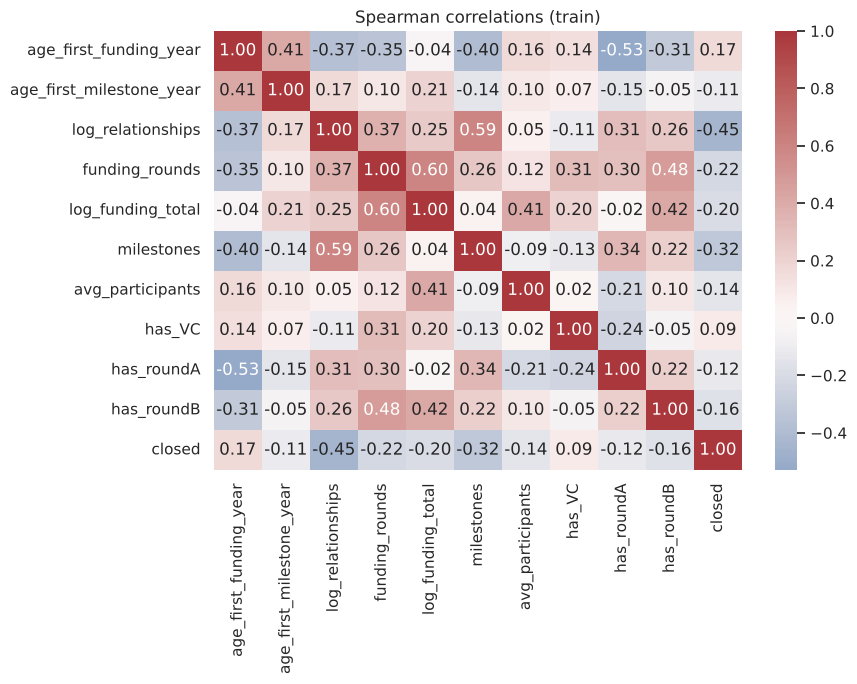

,feature,VIF
3,funding_rounds,3.249
4,log_funding_total,2.225
2,log_relationships,2.034
0,age_first_funding_year,2.026
5,milestones,1.962
21,has_roundA,1.859
19,has_VC,1.717
7,is_CA,1.694


In [11]:
corr_cols = NUM_FEATURES + ['has_VC', 'has_roundA', 'has_roundB', 'closed']
plt.figure(figsize=(9, 7))
sns.heatmap(train[corr_cols].corr(method='spearman'), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Spearman correlations (train)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig3_spearman.png', dpi=150); plt.show()

def vif_table(X):
    Xv = X.astype(float).fillna(X.median()).copy()
    Xv.insert(0, 'const', 1.0)
    return pd.DataFrame({'feature': Xv.columns[1:],
                         'VIF': [variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])]}
                        ).sort_values('VIF', ascending=False)
display(vif_table(train[FEATURES]).head(8))

**Interpretation.** Two pairs stand out. Rounds and total funding move together (ρ = 0.60). So do relationships and milestones (ρ = 0.59). Closure is most tied to relationships (ρ = −0.45) and milestones (ρ = −0.32). Later first funding goes with more closures (ρ = 0.17). It also goes with no Series A (ρ = −0.53). Redundancy is moderate, not severe. The largest VIF is 3.2 for `funding_rounds`. All are below 5, so logistic coefficients remain readable.

*Limitation:* Spearman captures monotone pairs only. It misses interactions.

## 5. PCA (fitted on training data only)

,component,explained,cumulative
0,PC1,0.323,0.323
1,PC2,0.232,0.555
2,PC3,0.161,0.716
3,PC4,0.120,0.836
4,PC5,0.065,0.901
5,PC6,0.057,0.957
6,PC7,0.043,1.000


Components for >= 80% cumulative variance: 4


,PC1,PC2
age_first_funding_year,-0.390,0.463
age_first_milestone_year,-0.034,0.496
avg_participants,0.050,0.476
log_funding_total,0.357,0.467
milestones,0.459,-0.224
funding_rounds,0.479,0.213
log_relationships,0.526,0.014


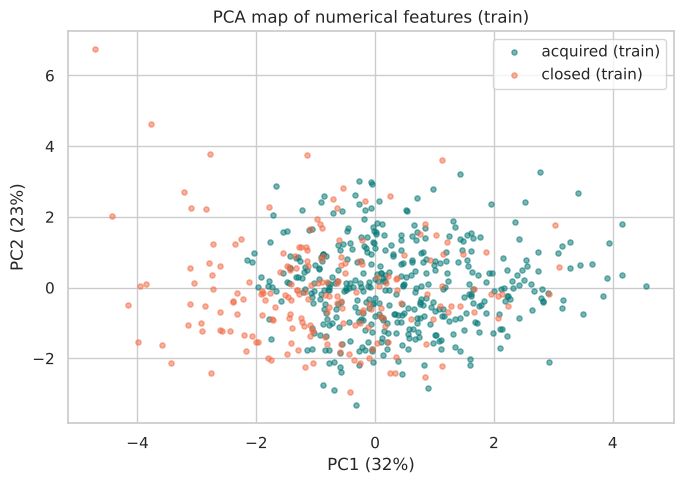

In [12]:
pca_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('pca', PCA(random_state=RANDOM_STATE))
])
Z_train = pca_pipe.fit_transform(train[NUM_FEATURES])
pca = pca_pipe.named_steps['pca']
evr = pd.DataFrame({'component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
                    'explained': pca.explained_variance_ratio_,
                    'cumulative': np.cumsum(pca.explained_variance_ratio_)})
display(evr)
n80 = int(np.argmax(evr['cumulative'].values >= 0.80) + 1)
print('Components for >= 80% cumulative variance:', n80)

loadings = pd.DataFrame(pca.components_[:2].T, index=NUM_FEATURES, columns=['PC1', 'PC2'])
display(loadings.sort_values('PC1'))

Z_test = pca_pipe.transform(test[NUM_FEATURES])
fig, ax = plt.subplots(figsize=(7, 5))
for label, color in [('acquired', '#0A7B78'), ('closed', '#F36F4B')]:
    m = train['status'].values == label
    ax.scatter(Z_train[m, 0], Z_train[m, 1], s=14, alpha=.55, color=color, label=f'{label} (train)')
ax.set(xlabel=f'PC1 ({evr.explained[0]:.0%})', ylabel=f'PC2 ({evr.explained[1]:.0%})',
       title='PCA map of numerical features (train)')
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / 'fig4_pca.png', dpi=150); plt.show()

**Interpretation.** PCA was fitted on the 590 training firms after median imputation and scaling. Four components are needed to reach 80% of variance (83.6%). The first two hold 55.5%.

- **PC1 (32%)** is track record. It loads on relationships (+0.53), funding rounds (+0.48) and milestones (+0.46). Late first funding pulls it down (−0.39).
- **PC2 (23%)** is late, large, syndicated rounds. It loads on milestone age (+0.50), avg participants (+0.48), funding (+0.47) and first-funding age (+0.46). Milestone count pulls it down (−0.22).

Closed firms gather at low PC1, but the two classes overlap. The map drops 45% of the variance and all binary features. It is not evidence of clusters or of class separation.

## 6. Classification: baseline, pipeline and cross-validation

In [13]:
POS = 1  # closed

def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                          ('scale', StandardScaler())]), NUM_FEATURES),
        ('bin', 'passthrough', BIN_FEATURES)
    ])

def metrics_row(name, partition, y_true, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {'model': name, 'partition': partition, 'n': len(y_true), 'threshold': threshold,
            'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'f1': f1_score(y_true, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, p) if len(np.unique(p)) > 1 else 0.5}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

baseline = DummyClassifier(strategy='most_frequent')
logit = Pipeline([('prep', make_preprocessor()),
                  ('model', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE))])
search = GridSearchCV(logit, {'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3]}, cv=cv, scoring='roc_auc')
search.fit(X_dev, y_dev)
best_C = search.best_params_['model__C']
display(pd.DataFrame(search.cv_results_)[['param_model__C', 'mean_test_score', 'std_test_score']].round(3))
print('Selected C (CV on development data only):', best_C)

logit.set_params(model__C=best_C)
forest = Pipeline([('prep', make_preprocessor()),
                   ('model', RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                                    class_weight='balanced', random_state=RANDOM_STATE))])

cv_rows = []
for name, model in [('Baseline (most frequent)', baseline), ('Logistic regression', logit), ('Random forest', forest)]:
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
    cv_rows.append({'model': name, 'partition': f'5-fold CV, development (n={len(y_dev)})',
                    **{m: res[f'test_{m}'].mean() for m in scoring},
                    'roc_auc_sd': res['test_roc_auc'].std()})
cv_table = pd.DataFrame(cv_rows)
display(cv_table)

,param_model__C,mean_test_score,std_test_score
0,0.010,0.795,0.034
1,0.030,0.797,0.032
2,0.100,0.792,0.030
3,0.300,0.787,0.028
4,1.000,0.782,0.026
5,3.000,0.780,0.025


Selected C (CV on development data only): 0.03


/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.13/site-packages/sklearn/metrics/_clas

,model,partition,accuracy,precision,recall,f1,roc_auc,roc_auc_sd
0,Baseline (most frequent),"5-fold CV, development (n=737)",0.672,0.000,0.000,0.000,0.500,0.000
1,Logistic regression,"5-fold CV, development (n=737)",0.719,0.559,0.703,0.621,0.797,0.032
2,Random forest,"5-fold CV, development (n=737)",0.750,0.615,0.645,0.628,0.803,0.032


### Threshold choice on the validation block

In [14]:
logit_tr = logit.fit(X_train, y_train)
p_val = logit_tr.predict_proba(X_val)[:, 1]
thr_rows = []
for t in np.arange(0.30, 0.71, 0.05):
    r = metrics_row('Logistic regression', 'validation', y_val, p_val, round(t, 2))
    r['f2'] = fbeta_score(y_val, (p_val >= t).astype(int), beta=2, zero_division=0)
    thr_rows.append(r)
thr_table = pd.DataFrame(thr_rows)
display(thr_table[['threshold', 'accuracy', 'precision', 'recall', 'f1', 'f2']])
# Rule fixed before test: highest threshold that keeps validation recall for 'closed' at 0.80 or more.
# Max-F2 sits at the edge of the grid (0.30) with precision below 0.45, so it is not used.
THRESHOLD = float(thr_table.loc[thr_table['recall'] >= 0.80, 'threshold'].max())
print('Selected threshold (validation recall >= 0.80, n=%d):' % len(y_val), THRESHOLD)

,threshold,accuracy,precision,recall,f1,f2
0,0.300,0.592,0.449,0.980,0.615,0.792
1,0.350,0.619,0.465,0.959,0.627,0.791
2,0.400,0.660,0.494,0.898,0.638,0.772
3,0.450,0.741,0.575,0.857,0.689,0.781
4,0.500,0.762,0.625,0.714,0.667,0.694
5,0.550,0.830,0.773,0.694,0.731,0.708
6,0.600,0.810,0.800,0.571,0.667,0.606
7,0.650,0.830,0.929,0.531,0.675,0.580
8,0.700,0.796,0.913,0.429,0.583,0.479


Selected threshold (validation recall >= 0.80, n=147): 0.45


**Interpretation.** The positive class is **closed**. For an investor, a false negative is the costly error: money goes into a firm that dies. A false positive costs a second look. I fixed the rule before touching test: take the highest threshold that keeps validation recall at 0.80 or more. That gives **0.45**. On validation (n = 147) it catches 85.7% of closed firms at precision 0.575. Maximising F2 was rejected. It picks 0.30, the edge of the grid, where precision falls below 0.45.

### Final test evaluation (run once)

,model,partition,n,threshold,accuracy,precision,recall,f1,roc_auc
0,Baseline (most frequent),test (n=185),185,0.500,0.546,0.000,0.000,0.000,0.500
1,Logistic regression,test (n=185),185,0.500,0.730,0.660,0.833,0.737,0.822
2,Logistic regression,test (n=185),185,0.450,0.692,0.615,0.857,0.716,0.822
3,Random forest,test (n=185),185,0.450,0.719,0.643,0.857,0.735,0.830


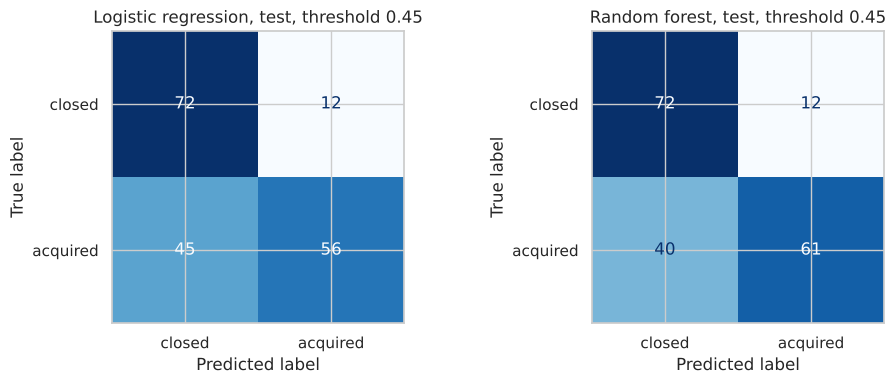

Test confusion matrix, logistic (rows = actual closed, acquired):
[[72 12]
 [45 56]]


In [15]:
baseline.fit(X_dev, y_dev)
logit.fit(X_dev, y_dev)
forest.fit(X_dev, y_dev)
p_base = baseline.predict_proba(X_test)[:, 1]
p_logit = logit.predict_proba(X_test)[:, 1]
p_forest = forest.predict_proba(X_test)[:, 1]

test_table = pd.DataFrame([
    metrics_row('Baseline (most frequent)', f'test (n={len(y_test)})', y_test, p_base, 0.5),
    metrics_row('Logistic regression', f'test (n={len(y_test)})', y_test, p_logit, 0.5),
    metrics_row('Logistic regression', f'test (n={len(y_test)})', y_test, p_logit, THRESHOLD),
    metrics_row('Random forest', f'test (n={len(y_test)})', y_test, p_forest, THRESHOLD),
])
display(test_table)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, p, title in [(axes[0], p_logit, 'Logistic regression'), (axes[1], p_forest, 'Random forest')]:
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= THRESHOLD).astype(int), labels=[1, 0],
                                            display_labels=['closed', 'acquired'], cmap='Blues',
                                            colorbar=False, ax=ax)
    ax.set_title(f'{title}, test, threshold {THRESHOLD}')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig5_confusion.png', dpi=150); plt.show()
print('Test confusion matrix, logistic (rows = actual closed, acquired):')
print(confusion_matrix(y_test, (p_logit >= THRESHOLD).astype(int), labels=[1, 0]))

**Interpretation.** The baseline always predicts "acquired". Its test accuracy is 0.546 and its recall is zero. It is useless for the task.

On the test set (n = 185, 84 closed), logistic regression at threshold 0.45 reaches ROC-AUC 0.822, recall 0.857 and precision 0.615. It catches 72 of 84 closed firms and misses 12. It also flags 45 of 101 acquired firms. Random forest is close: ROC-AUC 0.830, the same recall, precision 0.643. The gap is too small to justify a less transparent model.

Test ROC-AUC is slightly above cross-validation (0.797, SD 0.032, n = 737). This is not proof of better generalisation. The test base rate is higher, which shifts accuracy and precision. The ranking ability held up across time. That is the useful result.

### Coefficients: associations inside the fitted model, not causes

In [16]:
prep = logit.named_steps['prep']
names = [n.split('__')[-1] for n in prep.get_feature_names_out()]
coefs = pd.Series(logit.named_steps['model'].coef_[0], index=names).sort_values()
coef_table = pd.DataFrame({'coefficient': coefs, 'odds_ratio': np.exp(coefs)})
display(pd.concat([coef_table.head(6), coef_table.tail(6)]))

,coefficient,odds_ratio
log_relationships,-0.680,0.506
avg_participants,-0.226,0.798
log_funding_total,-0.207,0.813
is_MA,-0.150,0.861
milestones,-0.130,0.878
is_NY,-0.121,0.886
is_mobile,0.041,1.042
missingindicator_age_first_funding_year,0.056,1.058
is_TX,0.093,1.097
has_VC,0.146,1.157


**Interpretation.** Coefficients are per standard deviation for numeric features. Relationships carry the most weight. One SD more is associated with roughly half the odds of closure (OR 0.51). Average participants per round (OR 0.80) and total funding (OR 0.81) point the same way. Later first funding is associated with higher odds (OR 1.22). So is having no milestone (OR 1.31). `has_VC` is slightly positive after the other funding variables are held fixed. That is a conditional association, not a VC penalty. None of these are causal effects.

### Error analysis: 20 most confident errors on the test set

In [17]:
err = test[['id', 'name', 'founded_at', 'category_code', 'state_code', 'status', 'funding_total_usd',
            'funding_rounds', 'relationships', 'milestones', 'has_VC', 'has_roundA', 'age_first_funding_year']].copy()
err['p_closed'] = p_logit
err['pred'] = np.where(p_logit >= THRESHOLD, 'closed', 'acquired')
err['error'] = np.select([(err['status'] == 'closed') & (err['pred'] == 'acquired'),
                          (err['status'] == 'acquired') & (err['pred'] == 'closed')], ['FN', 'FP'], 'correct')
print(err['error'].value_counts())
fn = err[err['error'] == 'FN'].sort_values('p_closed').head(10)
fp = err[err['error'] == 'FP'].sort_values('p_closed', ascending=False).head(20 - len(fn))
worst = pd.concat([fn, fp])
display(worst.drop(columns=['id']))

prof_cols = ['funding_total_usd', 'funding_rounds', 'relationships', 'milestones', 'has_VC', 'has_roundA']
group_profile = err.groupby('error')[prof_cols].median()
group_profile['n'] = err['error'].value_counts()
group_profile['founded_2010_plus'] = err.groupby('error')['founded_at'].apply(lambda s: (s.dt.year >= 2010).mean())
display(group_profile)
display(err.groupby(['error'])['category_code'].agg(lambda s: s.value_counts().head(3).to_dict()))

error
correct    128
FP          45
FN          12
Name: count, dtype: int64


,name,founded_at,category_code,state_code,status,funding_total_usd,funding_rounds,relationships,milestones,has_VC,has_roundA,age_first_funding_year,p_closed,pred,error
870,Pipewise,2010-09-01,enterprise,CA,closed,3500000,1,16,2,0,1,0.463,0.208,acquired,FN
738,EvoApp,2009-01-01,analytics,NC,closed,3352194,3,8,2,0,1,1.786,0.218,acquired,FN
823,Loosecubes,2010-01-01,web,NY,closed,9030000,2,8,2,0,1,0.000,0.263,acquired,FN
865,Color Labs Inc.,2010-08-01,other,CA,closed,41000000,2,11,2,0,1,0.000,0.267,acquired,FN
816,Hashable,2010-01-01,mobile,NY,closed,4000000,1,15,2,0,1,0.890,0.270,acquired,FN
882,Wantful,2011-01-01,ecommerce,CA,closed,5500000,1,6,2,0,1,1.216,0.284,acquired,FN
874,Flud,2010-10-01,enterprise,CA,closed,2100000,3,12,2,1,0,0.531,0.293,acquired,FN
750,Fashism,2009-01-01,fashion,NY,closed,1000000,1,5,3,0,1,1.882,0.362,acquired,FN
919,Yub,2013-01-01,ecommerce,CA,closed,12000000,1,7,0,1,0,0.882,0.388,acquired,FN
831,Offermatic,2010-02-01,web,CA,closed,4500000,2,6,2,0,1,0.830,0.404,acquired,FN


,funding_total_usd,funding_rounds,relationships,milestones,has_VC,has_roundA,n,founded_2010_plus
error,,,,,,,,
FN,"3,750,000.000",1.500,7.500,2.000,0.000,1.000,12,0.750
FP,"1,500,000.000",2.000,4.000,2.000,0.000,0.000,45,0.578
correct,"1,206,533.000",2.000,5.000,2.000,0.000,0.000,128,0.633


error
FN         {'web': 3, 'enterprise': 2, 'ecommerce': 2}
FP          {'enterprise': 8, 'web': 6, 'software': 6}
correct    {'web': 33, 'mobile': 16, 'enterprise': 12}
Name: category_code, dtype: object

**Interpretation.** I inspected the 20 most confident errors on test: all 12 false negatives and the 8 strongest false positives. Three patterns stand out.

1. **Healthy-looking failures.** The missed closures had a median of 7.5 relationships and a Series A. On paper they resembled survivors. Color Labs raised $41M and still closed. The features cannot see product or market failure.
2. **Small acquisitions.** False positives are thin firms. Median funding is $1.5M and median relationships 4. Most are small software, web or enterprise firms. They were likely bought for the team or the code. An "acquired" label does not mean success.
3. **Short histories.** 75% of false negatives were founded in 2010 or later. Young firms had less time to collect funding and contacts. Counts that grow with age penalise them.

*Recommended check:* add the acquisition price where known, and compare errors by firm age at the data snapshot.

## 7. Clustering and stability

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,smallest_cluster,sizes,bootstrap_ARI
0,2,"2,715.750",0.214,178.462,1.634,239,"[239, 351]",0.763
1,3,"2,299.832",0.198,158.268,1.578,161,"[191, 238, 161]",0.625
2,4,"2,034.521",0.187,144.540,1.518,120,"[126, 192, 152, 120]",0.700
3,5,"1,843.873",0.182,134.531,1.487,96,"[104, 145, 102, 143, 96]",0.602
4,6,"1,704.785",0.188,125.736,1.447,17,"[86, 147, 111, 98, 131, 17]",0.630


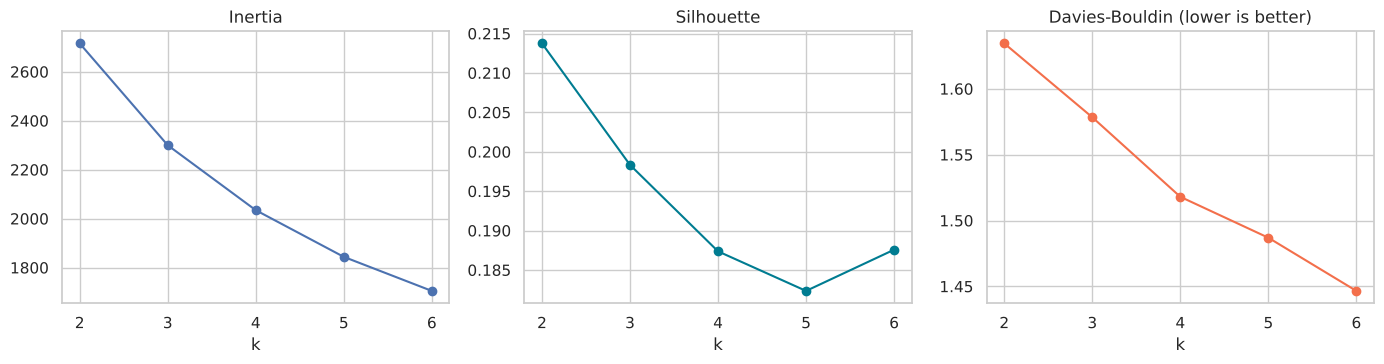

In [18]:
CLUSTER_FEATURES = ['log_funding_total', 'funding_rounds', 'log_relationships',
                    'milestones', 'avg_participants', 'age_first_funding_year']
cl_prep = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
C_train = cl_prep.fit_transform(train[CLUSTER_FEATURES])
C_test = cl_prep.transform(test[CLUSTER_FEATURES])

def internal_metrics(X, labels):
    return {'silhouette': silhouette_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels),
            'davies_bouldin': davies_bouldin_score(X, labels)}

km_rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(C_train)
    sizes = np.bincount(km.labels_)
    rng_k = np.random.default_rng(RANDOM_STATE)
    boot = []
    for b in range(20):
        idx = rng_k.choice(len(C_train), len(C_train), replace=True)
        boot.append(adjusted_rand_score(km.labels_, KMeans(n_clusters=k, n_init=20, random_state=b)
                                        .fit(C_train[idx]).predict(C_train)))
    km_rows.append({'k': k, 'inertia': km.inertia_, **internal_metrics(C_train, km.labels_),
                    'smallest_cluster': sizes.min(), 'sizes': sizes.tolist(), 'bootstrap_ARI': np.mean(boot)})
km_scores = pd.DataFrame(km_rows)
display(km_scores)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(km_scores['k'], km_scores['inertia'], marker='o'); axes[0].set(title='Inertia', xlabel='k')
axes[1].plot(km_scores['k'], km_scores['silhouette'], marker='o', color='#007C91'); axes[1].set(title='Silhouette', xlabel='k')
axes[2].plot(km_scores['k'], km_scores['davies_bouldin'], marker='o', color='#F36F4B'); axes[2].set(title='Davies-Bouldin (lower is better)', xlabel='k')
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig6_kmeans_k.png', dpi=150); plt.show()

In [19]:
K_SELECTED = 4
ref = KMeans(n_clusters=K_SELECTED, n_init=20, random_state=RANDOM_STATE).fit(C_train)
ref_labels = ref.labels_

# Stability 1: ten random seeds, single initialisation each
seed_ari = [adjusted_rand_score(ref_labels,
            KMeans(n_clusters=K_SELECTED, n_init=1, random_state=s).fit_predict(C_train)) for s in range(10)]
# Stability 2: twenty bootstrap resamples, refit, then label the full training set
rng = np.random.default_rng(RANDOM_STATE)
boot_ari = []
for b in range(20):
    idx = rng.choice(len(C_train), len(C_train), replace=True)
    km_b = KMeans(n_clusters=K_SELECTED, n_init=20, random_state=b).fit(C_train[idx])
    boot_ari.append(adjusted_rand_score(ref_labels, km_b.predict(C_train)))
# Stability 3: agreement with Ward on the same representation
ward_labels = AgglomerativeClustering(n_clusters=K_SELECTED, linkage='ward').fit_predict(C_train)

stab = pd.DataFrame([
    {'check': '10 seeds, n_init=1', 'mean_ARI': np.mean(seed_ari), 'min_ARI': np.min(seed_ari), 'max_ARI': np.max(seed_ari)},
    {'check': '20 bootstrap resamples', 'mean_ARI': np.mean(boot_ari), 'min_ARI': np.min(boot_ari), 'max_ARI': np.max(boot_ari)},
    {'check': 'Ward vs K-means', 'mean_ARI': adjusted_rand_score(ref_labels, ward_labels), 'min_ARI': np.nan, 'max_ARI': np.nan},
])
display(stab)

,check,mean_ARI,min_ARI,max_ARI
0,"10 seeds, n_init=1",0.619,0.297,0.957
1,20 bootstrap resamples,0.700,0.460,0.919
2,Ward vs K-means,0.240,NaN,NaN


In [20]:
prof = train[['funding_total_usd', 'funding_rounds', 'relationships', 'milestones',
              'avg_participants', 'age_first_funding_year']].copy()
prof['cluster'] = ref_labels
profile = prof.groupby('cluster').median()
profile['funding_total_usd'] = profile['funding_total_usd'] / 1e6
profile = profile.rename(columns={'funding_total_usd': 'median_funding_usd_m'})
profile.insert(0, 'size', prof['cluster'].value_counts().sort_index())
display(profile.round(2))

# Usefulness check: outcome used only AFTER clustering
use = pd.DataFrame({
    'train_n': pd.Series(ref_labels).value_counts().sort_index(),
    'train_closed_rate': pd.Series(train['closed'].values).groupby(ref_labels).mean(),
})
test_labels = ref.predict(C_test)
use['test_n'] = pd.Series(test_labels).value_counts().sort_index()
use['test_closed_rate'] = pd.Series(test['closed'].values).groupby(test_labels).mean()
display(use.round(3))

,size,median_funding_usd_m,funding_rounds,relationships,milestones,avg_participants,age_first_funding_year
cluster,,,,,,,
0,126,7.500,1.000,2.000,1.000,2.000,4.450
1,192,9.950,2.000,8.000,2.000,2.000,1.430
2,152,24.320,2.000,4.000,1.000,4.000,4.200
3,120,38.880,4.000,13.000,3.000,2.750,1.230


,train_n,train_closed_rate,test_n,test_closed_rate
0,126,0.675,50,0.880
1,192,0.208,102,0.333
2,152,0.303,22,0.273
3,120,0.183,11,0.000


**Interpretation.** I clustered the 590 training firms on six features: log funding, rounds, log relationships, milestones, avg participants and first-funding age. All were standardised, so Euclidean distance weights them equally. The outcome was not used.

No index gives a clear answer. Silhouette is low for every k (0.18–0.21). That means weak, overlapping structure. Silhouette and CH favour k = 2. Davies-Bouldin improves up to k = 6, but k = 6 creates a cluster of 17 firms. I chose **k = 4**. Its bootstrap ARI is 0.70, above k = 3 (0.63) and k = 5 (0.60). Its smallest cluster has 120 firms. Its profiles are distinct in original units.

| Cluster | Size | Profile (medians) | Name |
|---|---|---|---|
| 0 | 126 | $7.5M, 1 round, 2 relationships, first funding at 4.5 years | Thin late starters |
| 1 | 192 | $10.0M, 2 rounds, 8 relationships, 2 milestones, first funding at 1.4 years | Networked early starters |
| 2 | 152 | $24.3M, 2 rounds, 4 investors per round, first funding at 4.2 years | Late syndicated raisers |
| 3 | 120 | $38.9M, 4 rounds, 13 relationships, 3 milestones | Serial-funded leaders |

**Stability.** Twenty bootstrap refits give mean ARI 0.70 (min 0.46). Ten single-start seeds give 0.62 (min 0.30). Ward agrees with K-means at ARI 0.24 only. The solution is moderately stable for K-means. Its boundaries depend on the method.

**Usefulness.** Only after clustering did I look at outcomes. In train, 67.5% of Thin late starters closed, against 18.3% of Serial-funded leaders. On test, 88% of 50 Thin late starters closed. The segments carry signal. But 102 of 185 test firms fall in cluster 1 and only 11 in cluster 3. Young firms have not yet built a long history.

## 8. Text and multimedia suitability

In [21]:
text_like = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype) in ('str', 'string')]
print('Non-numeric columns:', text_like)
print('Distinct values in category_code:', raw['category_code'].nunique())
print('Mean word count of name:', raw['name'].astype(str).str.split().str.len().mean().round(2))

Non-numeric columns: ['state_code', 'zip_code', 'id', 'city', 'Unnamed: 6', 'name', 'founded_at', 'closed_at', 'first_funding_at', 'last_funding_at', 'state_code.1', 'category_code', 'object_id', 'status']
Distinct values in category_code: 35
Mean word count of name: 1.41


**Text and multimedia decision.**

| Question | Response |
|---|---|
| Genuine unstructured text, image or audio? | No. The non-numeric columns are identifiers, dates, place names and a 35-level category code. Names average 1.4 words. |
| Observation unit for this information | The startup. |
| Is Bag-of-Words or TF-IDF appropriate? | No. Turning category codes or city names into "documents" would only re-encode one-hot variables. The form forbids it. |
| Separating related authors, sources, periods | Not applicable now. A future text set would need a split by company and by founding year, as here. |
| Metric for a proposed task | ROC-AUC and recall for "closed" on a temporal test, to compare against the tabular model. |
| Privacy, bias, representation risk | Founder bios would hold personal data. Press coverage over-represents California and well-funded firms. |

**Future extension.** Collect each firm's company description as written at first funding. Encode it with TF-IDF or a sentence-embedding model. Fit it inside the same temporal split. Then test late fusion with the tabular model. Text written after the outcome, such as post-mortems, must be excluded.

## 9. Neural model comparison (small MLP)

,best_epoch,min_validation_loss,training_loss_at_best,validation_auc_at_best,final_training_loss,final_validation_loss,final_gap
0,38,0.472,0.464,0.812,0.395,0.661,0.266


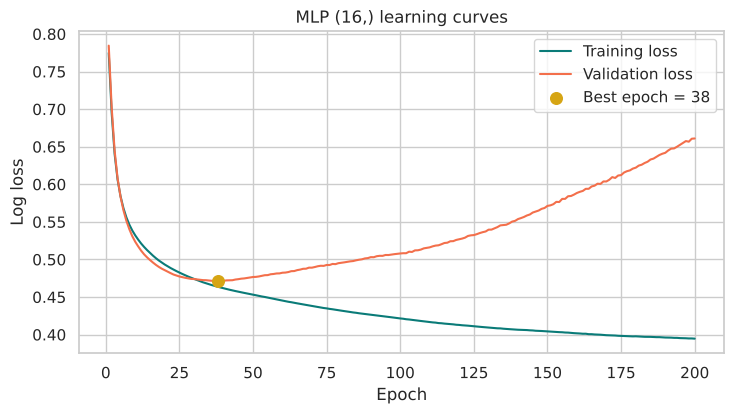

In [22]:
mlp_prep = make_preprocessor().fit(X_train)
Xtr_m, Xval_m, Xte_m = mlp_prep.transform(X_train), mlp_prep.transform(X_val), mlp_prep.transform(X_test)

def train_by_epoch(hidden_layer_sizes, alpha, learning_rate_init, epochs=200):
    model = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, activation='relu', solver='adam',
                          alpha=alpha, batch_size=32, learning_rate_init=learning_rate_init,
                          max_iter=1, warm_start=True, shuffle=True, random_state=RANDOM_STATE)
    history = []
    for epoch in range(1, epochs + 1):
        model.fit(Xtr_m, y_train)
        p_tr, p_v = model.predict_proba(Xtr_m)[:, 1], model.predict_proba(Xval_m)[:, 1]
        history.append({'epoch': epoch,
                        'training_loss': log_loss(y_train, p_tr), 'validation_loss': log_loss(y_val, p_v),
                        'training_auc': roc_auc_score(y_train, p_tr), 'validation_auc': roc_auc_score(y_val, p_v)})
    return model, pd.DataFrame(history)

MLP_ARCH, MLP_ALPHA, MLP_LR, MAX_EPOCHS = (16,), 1e-3, 0.001, 200
_, hist = train_by_epoch(MLP_ARCH, MLP_ALPHA, MLP_LR, MAX_EPOCHS)
best = hist.loc[hist['validation_loss'].idxmin()]
BEST_EPOCH = int(best['epoch'])
final = hist.iloc[-1]
display(pd.DataFrame([{
    'best_epoch': BEST_EPOCH, 'min_validation_loss': best['validation_loss'],
    'training_loss_at_best': best['training_loss'], 'validation_auc_at_best': best['validation_auc'],
    'final_training_loss': final['training_loss'], 'final_validation_loss': final['validation_loss'],
    'final_gap': final['validation_loss'] - final['training_loss']}]))

plt.figure(figsize=(7.5, 4.3))
plt.plot(hist['epoch'], hist['training_loss'], label='Training loss', color='#0A7B78')
plt.plot(hist['epoch'], hist['validation_loss'], label='Validation loss', color='#F36F4B')
plt.scatter(BEST_EPOCH, best['validation_loss'], color='#D6A514', s=70, zorder=5, label=f'Best epoch = {BEST_EPOCH}')
plt.xlabel('Epoch'); plt.ylabel('Log loss'); plt.title('MLP (16,) learning curves'); plt.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig7_mlp_curves.png', dpi=150); plt.show()

In [23]:
# Refit to the selected checkpoint on the same training data, then compare with logistic regression
mlp_final, _ = train_by_epoch(MLP_ARCH, MLP_ALPHA, MLP_LR, BEST_EPOCH)
p_mlp_val, p_mlp_test = mlp_final.predict_proba(Xval_m)[:, 1], mlp_final.predict_proba(Xte_m)[:, 1]
p_lr_val, p_lr_test = logit_tr.predict_proba(X_val)[:, 1], logit_tr.predict_proba(X_test)[:, 1]

nn_table = pd.DataFrame([
    {**metrics_row('Logistic regression (train only)', f'validation (n={len(y_val)})', y_val, p_lr_val, THRESHOLD), 'log_loss': log_loss(y_val, p_lr_val)},
    {**metrics_row(f'MLP {MLP_ARCH}, epoch {BEST_EPOCH}', f'validation (n={len(y_val)})', y_val, p_mlp_val, THRESHOLD), 'log_loss': log_loss(y_val, p_mlp_val)},
    {**metrics_row('Logistic regression (train only)', f'test (n={len(y_test)})', y_test, p_lr_test, THRESHOLD), 'log_loss': log_loss(y_test, p_lr_test)},
    {**metrics_row(f'MLP {MLP_ARCH}, epoch {BEST_EPOCH}', f'test (n={len(y_test)})', y_test, p_mlp_test, THRESHOLD), 'log_loss': log_loss(y_test, p_mlp_test)},
])
display(nn_table)

,model,partition,n,threshold,accuracy,precision,recall,f1,roc_auc,log_loss
0,Logistic regression (train only),validation (n=147),147,0.450,0.748,0.586,0.837,0.689,0.877,0.477
1,"MLP (16,), epoch 38",validation (n=147),147,0.450,0.782,0.730,0.551,0.628,0.812,0.472
2,Logistic regression (train only),test (n=185),185,0.450,0.692,0.615,0.857,0.716,0.822,0.542
3,"MLP (16,), epoch 38",test (n=185),185,0.450,0.676,0.676,0.548,0.605,0.742,0.629


**Interpretation.** The MLP uses the same preprocessing, the same train/validation boundary and the same metrics.

| Item | Response |
|---|---|
| Architecture and activation | One hidden layer of 16 ReLU units, logistic output, Adam, L2 alpha 0.001, batch 32, learning rate 0.001, seed 42 |
| Stopping rule and epochs | Maximum 200 epochs. Keep the epoch with the lowest validation log loss: epoch 38. Refit to 38 epochs. |
| Training and validation evidence | At epoch 38: train loss 0.464, validation loss 0.472. By epoch 200: 0.395 vs 0.661, a gap of 0.27. |
| Final-test result | ROC-AUC 0.742, recall 0.548, log loss 0.629 (n = 185). Logistic regression on the same training data: 0.822, 0.857, 0.542. |
| Does complexity help? | No. |

Learning is stable up to epoch 38. After that, training loss keeps falling and validation loss climbs. That is overfitting. Even at its best checkpoint, the network ranks firms worse than logistic regression on validation (0.812 vs 0.877) and on test. With 590 training firms and mostly monotone signals, extra capacity fits noise. Logistic regression stays the primary model.

## 10. Compact result table for the claim audit

In [24]:
summary = pd.concat([cv_table[['model', 'partition', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']],
                     test_table[['model', 'partition', 'threshold', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']]])
display(summary.round(3))
print(summary.round(3).to_markdown(index=False) if hasattr(summary, 'to_markdown') else summary.round(3))

,model,partition,accuracy,precision,recall,f1,roc_auc,threshold
0,Baseline (most frequent),"5-fold CV, development (n=737)",0.672,0.000,0.000,0.000,0.500,NaN
1,Logistic regression,"5-fold CV, development (n=737)",0.719,0.559,0.703,0.621,0.797,NaN
2,Random forest,"5-fold CV, development (n=737)",0.750,0.615,0.645,0.628,0.803,NaN
0,Baseline (most frequent),test (n=185),0.546,0.000,0.000,0.000,0.500,0.500
1,Logistic regression,test (n=185),0.730,0.660,0.833,0.737,0.822,0.500
2,Logistic regression,test (n=185),0.692,0.615,0.857,0.716,0.822,0.450
3,Random forest,test (n=185),0.719,0.643,0.857,0.735,0.830,0.450


| model                    | partition                      |   accuracy |   precision |   recall |    f1 |   roc_auc |   threshold |
|:-------------------------|:-------------------------------|-----------:|------------:|---------:|------:|----------:|------------:|
| Baseline (most frequent) | 5-fold CV, development (n=737) |      0.672 |       0     |    0     | 0     |     0.5   |      nan    |
| Logistic regression      | 5-fold CV, development (n=737) |      0.719 |       0.559 |    0.703 | 0.621 |     0.797 |      nan    |
| Random forest            | 5-fold CV, development (n=737) |      0.75  |       0.615 |    0.645 | 0.628 |     0.803 |      nan    |
| Baseline (most frequent) | test (n=185)                   |      0.546 |       0     |    0     | 0     |     0.5   |        0.5  |
| Logistic regression      | test (n=185)                   |      0.73  |       0.66  |    0.833 | 0.737 |     0.822 |        0.5  |
| Logistic regression      | test (n=185)                   | 

## 11. Analytical claim audit

**Tool:** Claude (Anthropic), chat interface. The compact table above was pasted as Markdown.

**Exact prompt:**

> Below is a compact results table from my analysis of 922 US startups. The target is whether a startup closed (positive class) or was acquired. Write five short statements that summarise what these results show.
>
> *(table from Section 10 pasted here)*

**Exact output:**

> 1. Logistic regression achieved a test ROC-AUC of 0.822, well above the baseline of 0.500.
> 2. Random forest is the best model, outperforming logistic regression on every metric.
> 3. The model correctly identifies 86% of startups that will close.
> 4. Accuracy rose from 0.719 in cross-validation to 0.730 on the test set, showing that the model generalises well to new data.
> 5. Startups with more relationships and funding are less likely to fail, so building a network causes success.

**Audit against the notebook:**

| Claim | Status | Evidence location | Corrected wording |
|---|---|---|---|
| 1 | Supported | Section 6, final test table | Logistic regression reached ROC-AUC 0.822 on the temporal test set (n = 185); the most-frequent baseline scores 0.500. |
| 2 | Contradicted | Section 6, CV and test tables | Random forest had slightly higher ROC-AUC (0.803 vs 0.797 in CV; 0.830 vs 0.822 on test) but lower CV recall (0.645 vs 0.703). Test recall was equal (0.857). |
| 3 | Overstated | Section 6, confusion matrix | At threshold 0.45 the model flagged 72 of 84 closed firms founded 2009–2013 (recall 0.857). Nothing in the analysis shows performance on future firms. |
| 4 | Unsupported | Sections 3 and 6 | CV and test use different firms and base rates (0.33 vs 0.45 closed). Accuracy 0.730 is at threshold 0.50; at the chosen 0.45 it is 0.692. Baseline accuracy fell from 0.672 to 0.546, so accuracy cannot be compared across partitions. |
| 5 | Unsupported | Section 6, coefficients | More relationships are associated with lower predicted odds of closure (OR 0.51 per SD). The design is observational and the counts grow with survival, so no causal claim is possible. |

Fluent wording made claims 2–5 sound certain. Each needed the notebook to check.

## 12. Final conclusions

| Required conclusion | Response |
|---|---|
| Main evidence-based finding | Pre-exit funding history ranks startups by risk of closure. On firms founded 2009–2013 (n = 185), logistic regression reached ROC-AUC 0.822 against 0.500 for the baseline, catching 72 of 84 closures. |
| Second finding | Network size is the strongest single signal. 70% of firms with 0–2 relationships closed, against 9% with 11 or more (train, n = 590). |
| Third finding | Four funding profiles emerge with moderate stability (bootstrap ARI 0.70). Their closure rates range from 18% to 68% in train. More model complexity did not help: the MLP overfit after 38 epochs and scored ROC-AUC 0.742. |
| Most important limitation | Counts such as relationships, rounds and milestones grow while a firm is alive. Closed firms had less time to collect them. Part of the signal may be survival time, not quality. |
| Second limitation | The extract holds only resolved outcomes from one source. All 26 pre-2000 firms closed. "Acquired" mixes large exits with small acqui-hires. |
| Practical recommendation | Use the model as a screening flag, not a verdict. At threshold 0.45, send flagged firms to manual due diligence. Expect about 4 in 10 flags to be false alarms. |
| What should be tested next | Rebuild features at a fixed age, for example two years after founding, so all firms have equal exposure. Then repeat the temporal test and check whether ROC-AUC holds. |